Dataset Shape: (569, 30)
Features: 30
Classes: ['malignant' 'benign']

Model: Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



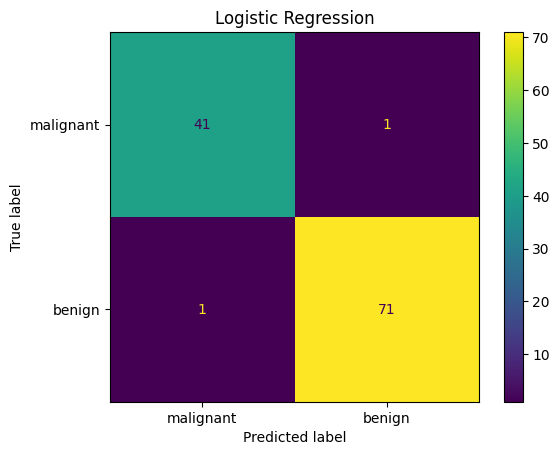


Model: SVM
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



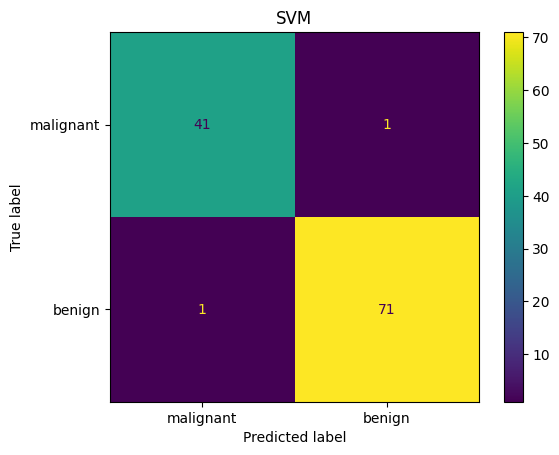


Model: Random Forest
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



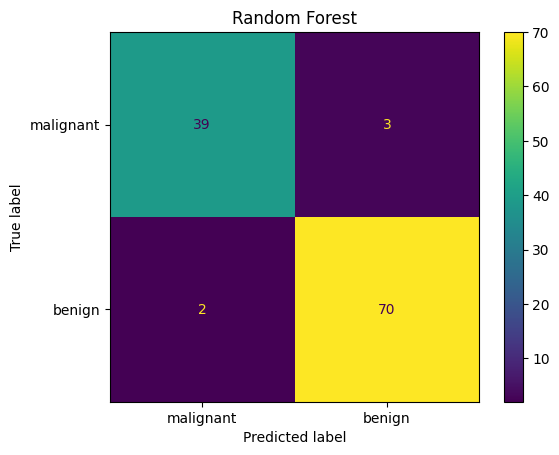


MODEL COMPARISON
                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9825     0.9861  0.9861    0.9861
1                  SVM    0.9825     0.9861  0.9861    0.9861
2        Random Forest    0.9561     0.9589  0.9722    0.9655

Execution completed successfully!


In [1]:

# BREAST CANCER DETECTION USING MACHINE LEARNING

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

print("Dataset Shape:", X.shape)
print("Features:", len(data.feature_names))
print("Classes:", data.target_names)

# 2. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Define classification models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC())
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

# 4. Train and evaluate models
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\nModel:", name)

    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    ))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=data.target_names
    )

    display.plot()
    plt.title(name)
    plt.show()

# 5. Display comparison
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(results_df.round(4))

# 6. Save results
results_df.to_csv("model_results.csv", index=False)

print("\nExecution completed successfully!")
